# 01 — Viabilidade: alerta antecipado de Sprint com o TAWOS

Este notebook apenas **lê** as saídas geradas por `scripts/rodar_tudo.sh` (consultas em `sql/`, reconstrução em `src/data/`, variáveis em `src/features/`, sinal em `src/analise_sinal.py`). Para recalcular tudo a partir do MySQL, rode a célula opcional abaixo. O texto completo está em `reports/viabilidade_scrum.md`.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
RECALCULAR = False  # True: reexecuta todo o pipeline (requer o MySQL com o dump importado)
if RECALCULAR:
    import subprocess; subprocess.run(['scripts/rodar_tudo.sh'], check=True)

## Etapa 1 — Inventário (P1, P2, P3)

In [2]:
inv = pd.read_csv('data/interim/inventario_projetos.csv', index_col=0).sort_values('n_sprints', ascending=False)
inv[['n_sprints','com_start_end','dur_q1','dur_mediana','dur_q3','pct_7a28','itens_ligados_mediana','aderente_scrum','pct_com_sp_no_inicio','sprints_c_comprometidos']].round(2)

,n_sprints,com_start_end,dur_q1,dur_mediana,dur_q3,pct_7a28,itens_ligados_mediana,aderente_scrum,pct_com_sp_no_inicio,sprints_c_comprometidos
projeto,,,,,,,,,,
CONFSERVER,565,560,7.00,13.00,14.00,0.92,1.0,True,0.36,450
CONFCLOUD,477,470,7.00,11.00,14.00,0.89,0.0,True,0.18,190
DM,396,393,13.00,26.12,29.62,0.64,20.0,False,0.90,332
MULE,311,298,14.00,14.00,14.00,0.99,7.0,True,0.85,261
TIMOB,301,301,11.61,14.00,14.00,0.99,11.0,True,0.76,257
MESOS,227,227,14.00,14.00,14.00,0.99,9.0,True,0.71,199
TIDOC,217,215,7.00,7.00,14.00,0.81,3.0,True,0.65,176
TISTUD,163,163,11.45,13.96,14.00,1.00,5.0,True,0.84,136
MDL,151,150,14.00,17.34,18.33,0.97,6.0,True,0.69,85


In [3]:
campos = pd.read_csv('data/raw/csv/03_changelog_campos.csv')
campos[campos.field.isin(['Sprint','status','resolution','Story Points','Flagged','Rank'])]

,change_type,field,n
5,OTHER,Rank,455498
10,OTHER,Sprint,174915
188,OTHER,Flagged,455
429,STATUS,status,1363475
430,STATUS,resolution,416202
431,STORY_POINT,Story Points,48225


In [4]:
from src.data.reconstrucao import STATUS_CONCLUIDO, normalizar_status
t = pd.read_csv('data/raw/csv/04_transicoes_status.csv')
t['para_n'] = t.para.map(normalizar_status)
(t[t.para_n.isin(STATUS_CONCLUIDO)].groupby(['projeto','para']).n.sum().unstack(fill_value=0))

para,Closed,Complete,Done,Resolved
projeto,,,,
ALOY,255,0,0,341
APIKIT,335,0,196,299
APSTUD,2,0,0,5
BAM,48,0,0,47
BE,0,167,359,0
CLI,247,0,0,304
CLOV,232,0,0,171
COMPASS,816,0,0,1
CONFCLOUD,1494,0,0,335


## Etapa 2 — Amostra de prova de conceito (20 Sprints de MESOS, MULE e TIMOB)

In [5]:
am = pd.read_csv('data/interim/amostra_poc.csv')
am[['projeto','sprint_id','sprint_nome','n_comprometidos','cobertura_sp','sp_comprometidos','n_adicionados','n_removidos','n_concluidos_antes_inicio','frac_sp','cumpriu_L80','cumpriu_L90','cumpriu_L100','monotono','restante_final_confere']].round(2)

,projeto,sprint_id,sprint_nome,n_comprometidos,cobertura_sp,sp_comprometidos,n_adicionados,n_removidos,n_concluidos_antes_inicio,frac_sp,cumpriu_L80,cumpriu_L90,cumpriu_L100,monotono,restante_final_confere
0,MESOS,400,Mesosphere Sprint 53,5,0.80,17.0,23.0,0.0,3.0,0.59,0,0,0,True,True
1,MESOS,425,Mesosphere Sprint 28,62,0.87,179.0,22.0,1.0,1.0,0.45,0,0,0,True,True
2,MESOS,341,Storage R9 Sprint 36,7,1.00,18.0,1.0,0.0,0.0,0.17,0,0,0,True,True
3,MESOS,316,Containerization: RI-13 Sp 44,7,0.86,24.0,2.0,1.0,0.0,0.67,0,0,0,True,True
4,MESOS,473,Twitter Mesos Q4 Sprint 4,13,1.00,59.0,4.0,3.0,0.0,0.36,0,0,0,True,True
5,MESOS,421,Mesosphere Sprint 32,46,0.83,133.0,45.0,4.0,3.0,0.65,0,0,0,True,True
6,MESOS,402,Mesosphere Sprint 51,9,0.78,32.0,12.0,0.0,5.0,0.19,0,0,0,True,True
7,MULE,4448,ESB Himalaya 4,12,1.00,93.0,15.0,0.0,0.0,1.00,1,1,1,True,True
8,MULE,4390,Mule 4 M2 - Sprint 2,13,1.00,106.0,12.0,3.0,1.0,0.41,0,0,0,True,True
9,MULE,4407,SDK Nero 2,10,1.00,68.0,10.0,0.0,0.0,1.00,1,1,1,True,True


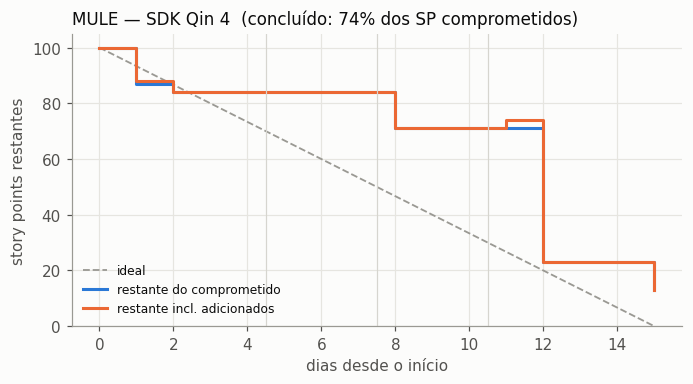

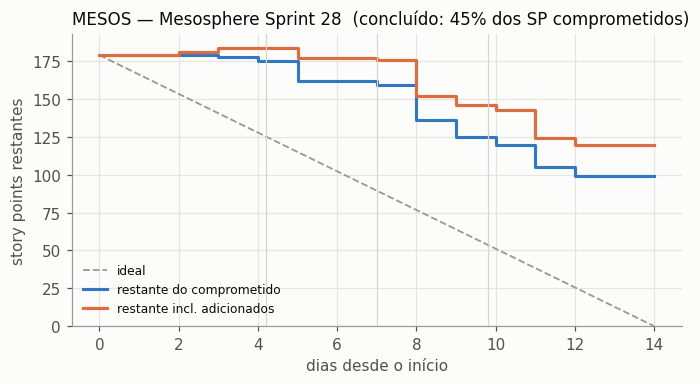

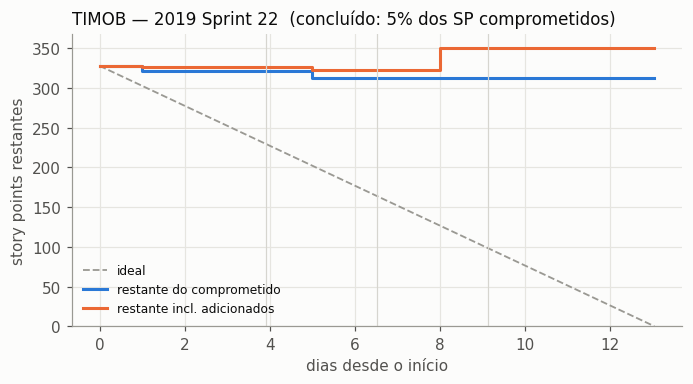

In [6]:
for f in ['MULE_4351', 'MESOS_425', 'TIMOB_4697']:
    display(Image(f'reports/figures/burndown_amostra/{f}.png'))

## Etapa 3 — Base de modelagem

In [7]:
display(pd.read_csv('data/processed/base_filtros.csv'))
base = pd.read_csv('data/processed/base_modelagem.csv')
base.head()

,etapa,n_sprints
0,Sprints na tabela Sprint,4594
1,com Start_Date e End_Date válidos,4542
2,State = CLOSED,4506
3,duração 5-31 dias,4323
4,>= 5 itens comprometidos,2027
5,cobertura de SP >= 70%,1166
6,SP comprometidos > 0,1166


,sprint_id,projeto,sprint_nome,start_date,end_date,duracao_dias,n_comprometidos,sp_comprometidos,cobertura_sp,usa_sp,compromisso_vs_velocidade,compromisso_vs_velocidade_itens,frac_sp_final,frac_itens_final,cumpriu_sp_L80,cumpriu_itens_L80,cumpriu_sp_L90,cumpriu_itens_L90,cumpriu_sp_L100,cumpriu_itens_L100,k,pct_tempo,pct_pontos_concluidos,pct_itens_concluidos,pontos_adicionados_rel,itens_adicionados_rel,pontos_removidos_rel,itens_removidos_rel,itens_em_andamento_rel
0,64,XD,Sprint 3,2013-05-15 00:37:45,2013-05-20 00:37:45,5.0,19,89.0,1.0,True,NaN,NaN,0.258427,0.368421,0.0,0,0.0,0,0.0,0,0.3,0.3,0.134831,0.157895,0.000000,0.000000,0.000000,0.000000,0.526316
1,64,XD,Sprint 3,2013-05-15 00:37:45,2013-05-20 00:37:45,5.0,19,89.0,1.0,True,NaN,NaN,0.258427,0.368421,0.0,0,0.0,0,0.0,0,0.5,0.5,0.258427,0.368421,0.022472,0.052632,0.146067,0.052632,0.421053
2,64,XD,Sprint 3,2013-05-15 00:37:45,2013-05-20 00:37:45,5.0,19,89.0,1.0,True,NaN,NaN,0.258427,0.368421,0.0,0,0.0,0,0.0,0,0.7,0.7,0.258427,0.368421,0.022472,0.052632,0.146067,0.052632,0.421053
3,62,XD,Sprint 5,2013-05-28 17:25:33,2013-06-03 17:25:33,6.0,21,60.0,1.0,True,2.5,1.702703,0.533333,0.666667,0.0,0,0.0,0,0.0,0,0.3,0.3,0.350000,0.428571,0.400000,0.285714,0.000000,0.000000,0.476190
4,62,XD,Sprint 5,2013-05-28 17:25:33,2013-06-03 17:25:33,6.0,21,60.0,1.0,True,2.5,1.702703,0.533333,0.666667,0.0,0,0.0,0,0.0,0,0.5,0.5,0.533333,0.666667,0.483333,0.333333,0.016667,0.047619,0.333333


In [8]:
s = base[base.k == 0.5]
pd.DataFrame({'SP (cobertura >= 70%)': [len(s[s.usa_sp])] + [s[s.usa_sp].frac_sp_final.ge(L - 1e-9).mean() for L in (0.6, 0.8, 0.9, 1.0)],
              'itens': [len(s)] + [s.frac_itens_final.ge(L - 1e-9).mean() for L in (0.6, 0.8, 0.9, 1.0)]},
             index=['n Sprints', '% cumpriu L=0,6', '% cumpriu L=0,8', '% cumpriu L=0,9', '% cumpriu L=1,0']).round(3)

,SP (cobertura >= 70%),itens
n Sprints,1166.000,2027.000
"% cumpriu L=0,6",0.252,0.300
"% cumpriu L=0,8",0.109,0.130
"% cumpriu L=0,9",0.059,0.051
"% cumpriu L=1,0",0.033,0.029


## Etapa 4 — Sinal: baselines × modelos, por k

**Cenário principal (decisões D1 e D2, `reports/decisoes.md`): SP, L = 0,8.** Robustez: itens, L = 0,8. L = 0,6 é só sensibilidade.

In [9]:
r = pd.read_csv('reports/resultados_sinal.csv')
r.pivot_table(index=['cenario','divisao','modelo'], columns='k', values=['auc','acuracia_balanceada','f1'], sort=False).round(3)

auc               acuracia_balanceada                   f1              
k                                                                  0.3    0.5    0.7                 0.3    0.5    0.7    0.3    0.5    0.7
cenario      divisao                modelo                                                                                                 
SP, L=0,8    GroupKFold por projeto B0 — classe majoritária        NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                                    B1 — burndown ideal          0.769  0.847  0.904               0.697  0.680  0.675  0.440  0.462  0.497
                                    Regressão logística          0.781  0.846  0.902               0.735  0.782  0.804  0.383  0.450  0.472
                                    MLP (1 camada, 8 neurônios)  0.728  0.821  0.889               0.674  0.746  0.819  0.330  0.433  0.510
             temporal por projeto   B0 — classe majoritária        NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                                    B1 — burndown ideal          0.761  0.864  0.919               0.713  0.683  0.647  0.463  0.469  0.449
                                    Regressão logística          0.803  0.882  0.924               0.704  0.800  0.817  0.371  0.500  0.500
                                    MLP (1 camada, 8 neurônios)  0.811  0.883  0.925               0.743  0.805  0.803  0.406  0.514  0.509
SP, L=0,6    GroupKFold por projeto B0 — classe majoritária        NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                                    B1 — burndown ideal          0.734  0.832  0.878               0.646  0.630  0.599  0.459  0.418  0.330
                                    Regressão logística          0.760  0.838  0.878               0.688  0.771  0.799  0.528  0.630  0.663
                                    MLP (1 camada, 8 neurônios)  0.755  0.831  0.876               0.692  0.761  0.788  0.531  0.618  0.648
             temporal por projeto   B0 — classe majoritária        NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                                    B1 — burndown ideal          0.736  0.842  0.914               0.665  0.645  0.585  0.483  0.449  0.289
                                    Regressão logística          0.790  0.858  0.907               0.709  0.770  0.850  0.517  0.598  0.693
                                    MLP (1 camada, 8 neurônios)  0.805  0.864  0.919               0.735  0.796  0.841  0.546  0.620  0.682
itens, L=0,8 GroupKFold por projeto B0 — classe majoritária        NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                                    B1 — burndown ideal          0.812  0.871  0.911               0.737  0.755  0.756  0.497  0.572  0.651
                                    Regressão logística          0.830  0.880  0.914               0.757  0.800  0.841  0.455  0.510  0.567
                                    MLP (1 camada, 8 neurônios)  0.823  0.873  0.912               0.736  0.780  0.840  0.433  0.503  0.580
             temporal por projeto   B0 — classe majoritária        NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                                    B1 — burndown ideal          0.797  0.876  0.924               0.743  0.733  0.739  0.494  0.526  0.629
                                    Regressão logística          0.837  0.885  0.923               0.760  0.792  0.853  0.469  0.508  0.571
                                    MLP (1 camada, 8 neurônios)  0.828  0.879  0.926               0.733  0.776  0.858  0.442  0.487  0.586
itens, L=0,6 GroupKFold por projeto B0 — classe majoritária        NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                                    B1 — burndown ideal          0.783  0.855  0.899               0.694  0.687  0.632  0.565  0.547  0.418
       

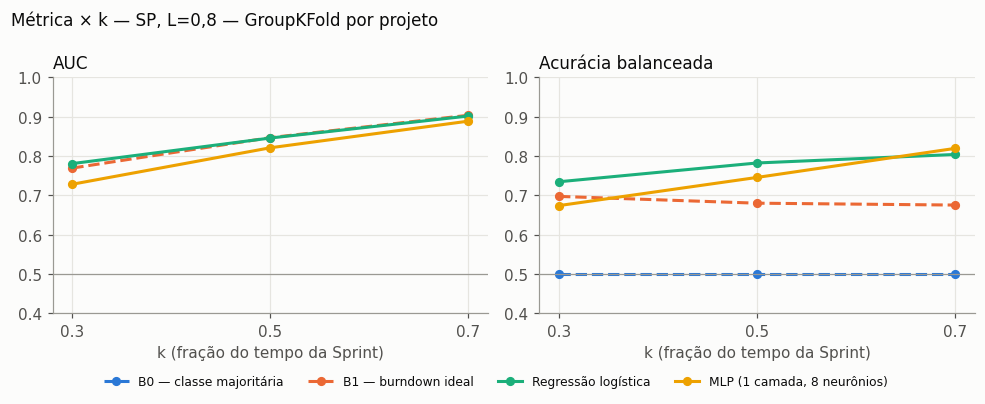

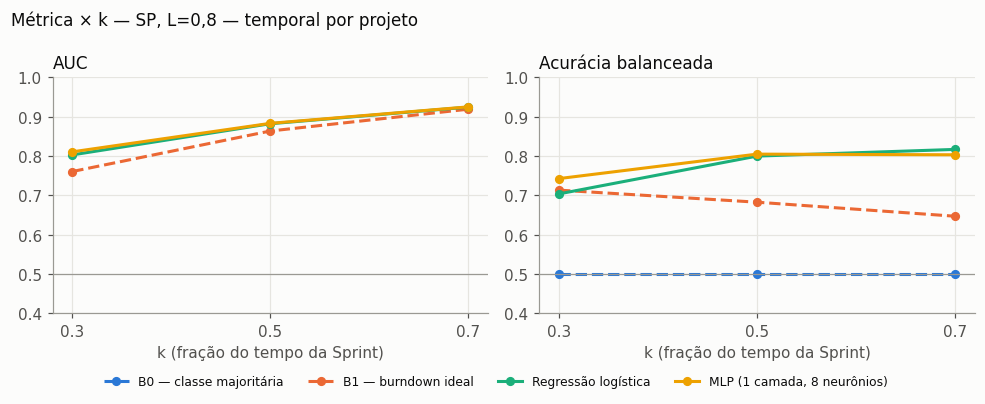

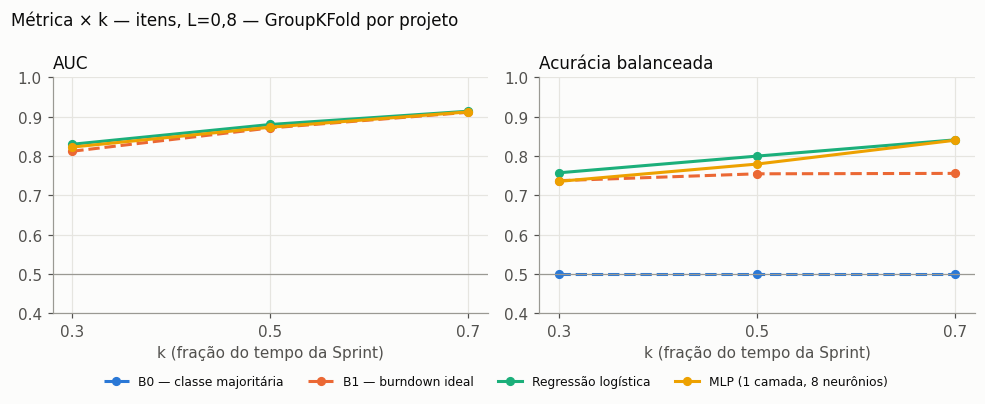

In [10]:
for f in ['SP_L08_group', 'SP_L08_temporal', 'itens_L08_group']:
    display(Image(f'reports/figures/metrica_vs_k_{f}.png'))

In [11]:
pd.read_csv('reports/ablacao_variaveis.csv').pivot_table(index=['cenario','variaveis'], columns='k', values='auc', sort=False).round(3)

k                                                     0.3    0.5    0.7
cenario      variaveis                                                 
SP, L=0,8    só burndown (pct_tempo + % concluído)  0.772  0.847  0.904
             todas                                  0.781  0.846  0.902
             todas − compromisso_vs_velocidade      0.768  0.845  0.903
             todas − itens_em_andamento_rel         0.785  0.847  0.901
             todas − adicionados_rel                0.785  0.848  0.904
SP, L=0,6    só burndown (pct_tempo + % concluído)  0.734  0.834  0.878
             todas                                  0.760  0.838  0.878
             todas − compromisso_vs_velocidade      0.720  0.826  0.872
             todas − itens_em_andamento_rel         0.767  0.841  0.881
             todas − adicionados_rel                0.763  0.838  0.879
itens, L=0,8 só burndown (pct_tempo + % concluído)  0.808  0.870  0.910
             todas                                  0.830  0.880  0.914
             todas − compromisso_vs_velocidade      0.799  0.868  0.908
             todas − itens_em_andamento_rel         0.832  0.877  0.910
             todas − adicionados_rel                0.832  0.880  0.913
itens, L=0,6 só burndown (pct_tempo + % concluído)  0.778  0.854  0.898
             todas                                  0.795  0.859  0.898
             todas − compromisso_vs_velocidade      0.769  0.846  0.892
             todas − itens_em_andamento_rel         0.799  0.860  0.898
             todas − adicionados_rel                0.792  0.857  0.896

## Modelagem — Perceptron, Adaline e PMC

Resultados de `scripts/experimentos.sh` (texto completo em `reports/resultados.md`).

,rede,semente,w0_limiar,w1_pct_tempo,w2_pct_concluido,epocas,convergiu,erro_final,fronteira_em_k05,acuracia_balanceada_treino
0,Perceptron,1,2.176,-5.171,8.460,100,False,2359.000,0.048,0.615
1,Perceptron,2,3.513,0.364,7.666,100,False,3117.000,-0.482,0.500
2,Perceptron,3,-2.385,-3.219,6.058,100,False,317.000,0.659,0.609
3,Perceptron,4,-1.101,-4.361,9.765,100,False,541.000,0.336,0.766
4,Perceptron,5,2.516,-1.648,8.852,100,False,3117.000,-0.191,0.500
5,Adaline,1,-0.132,-1.158,2.239,58,True,0.328,0.318,0.774
6,Adaline,2,-0.116,-1.146,2.238,56,True,0.328,0.308,0.770
7,Adaline,3,-0.135,-1.157,2.241,55,True,0.328,0.318,0.773
8,Adaline,4,-0.119,-1.156,2.248,60,True,0.328,0.310,0.771
9,Adaline,5,-0.126,-1.149,2.240,62,True,0.328,0.313,0.772


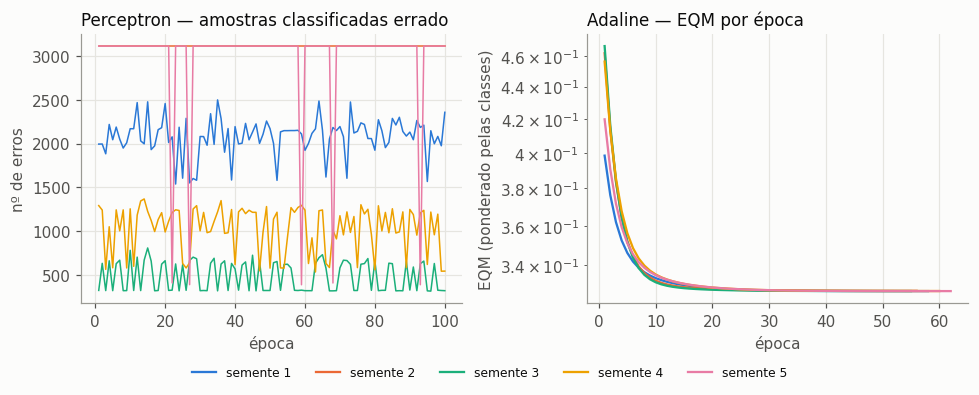

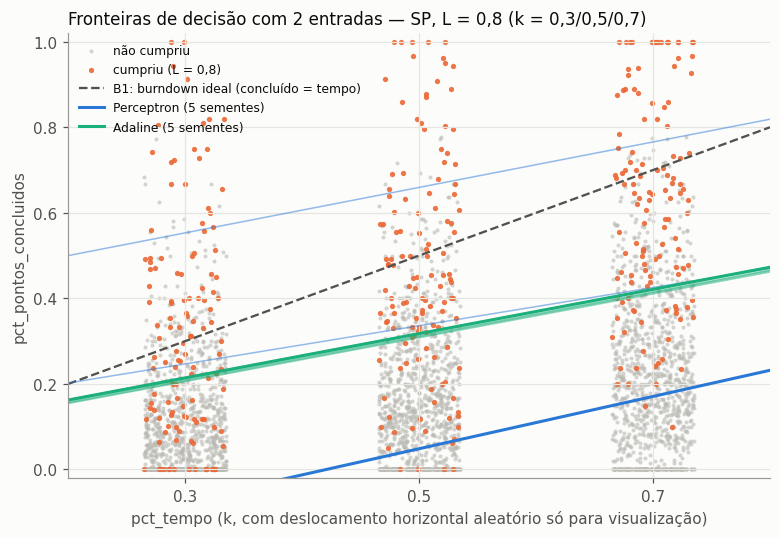

In [12]:
display(pd.read_csv('reports/resultados/exp1_perceptron_adaline_2entradas.csv').round(3))
display(Image('reports/figures/redes/exp1_curvas_treinamento.png'))
display(Image('reports/figures/redes/exp2_fronteiras_2entradas.png'))

,n_ocultos,auc_fora_da_dobra,auc_media_por_dobra,auc_dp_por_dobra
0,5,0.789,0.726,0.113
1,10,0.798,0.734,0.104
2,15,0.792,0.689,0.193


,semente,n_ocultos,erro_final_entropia_cruzada,epocas,convergiu,acuracia_balanceada_treino,auc_treino
0,1,10,0.396,2000,False,0.828,0.903
1,2,10,0.398,2000,False,0.826,0.903
2,3,10,0.391,2000,False,0.824,0.900
3,4,10,0.396,2000,False,0.816,0.901
4,5,10,0.406,2000,False,0.808,0.895


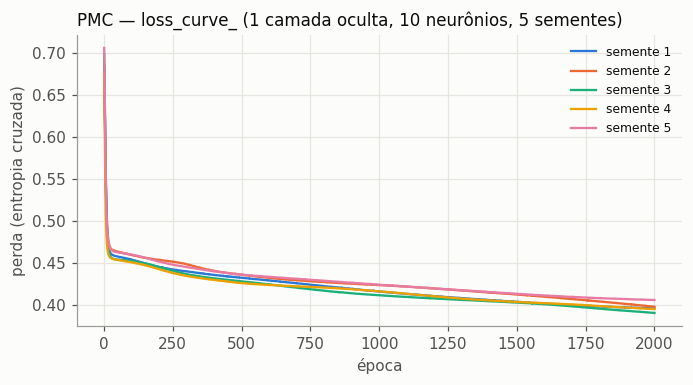

In [13]:
display(pd.read_csv('reports/resultados/exp3_pmc_topologias_cv.csv').round(3))
display(pd.read_csv('reports/resultados/exp3_pmc_treinamentos.csv').round(3))
display(Image('reports/figures/redes/exp3_pmc_loss_curve.png'))

auc               acuracia_balanceada                   f1              
k                                              0.3    0.5    0.7                 0.3    0.5    0.7    0.3    0.5    0.7
cenario             modelo                                                                                             
SP, L = 0,8         B0 — classe majoritária    NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                    B1 — burndown ideal      0.769  0.847  0.904               0.697  0.680  0.675  0.440  0.462  0.497
                    Perceptron               0.725  0.709  0.603               0.683  0.663  0.549  0.301  0.310  0.205
                    Adaline                  0.788  0.852  0.904               0.731  0.784  0.817  0.394  0.458  0.486
                    PMC                      0.683  0.777  0.856               0.631  0.717  0.755  0.276  0.386  0.435
itens, L = 0,8      B0 — classe majoritária    NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                    B1 — burndown ideal      0.812  0.871  0.911               0.737  0.755  0.756  0.497  0.572  0.651
                    Perceptron               0.779  0.831  0.853               0.710  0.771  0.774  0.391  0.484  0.519
                    Adaline                  0.827  0.883  0.918               0.738  0.805  0.836  0.443  0.514  0.543
                    PMC                      0.809  0.864  0.906               0.749  0.781  0.823  0.443  0.488  0.560
SP, L = 0,8, sem DM B0 — classe majoritária    NaN    NaN    NaN               0.500  0.500  0.500  0.000  0.000  0.000
                    B1 — burndown ideal      0.765  0.838  0.892               0.691  0.677  0.677  0.450  0.466  0.503
                    Perceptron               0.703  0.760  0.796               0.651  0.712  0.715  0.329  0.389  0.387
                    Adaline                  0.767  0.830  0.883               0.711  0.768  0.789  0.421  0.482  0.496
                    PMC                      0.703  0.769  0.840               0.670  0.713  0.768  0.376  0.428  0.491

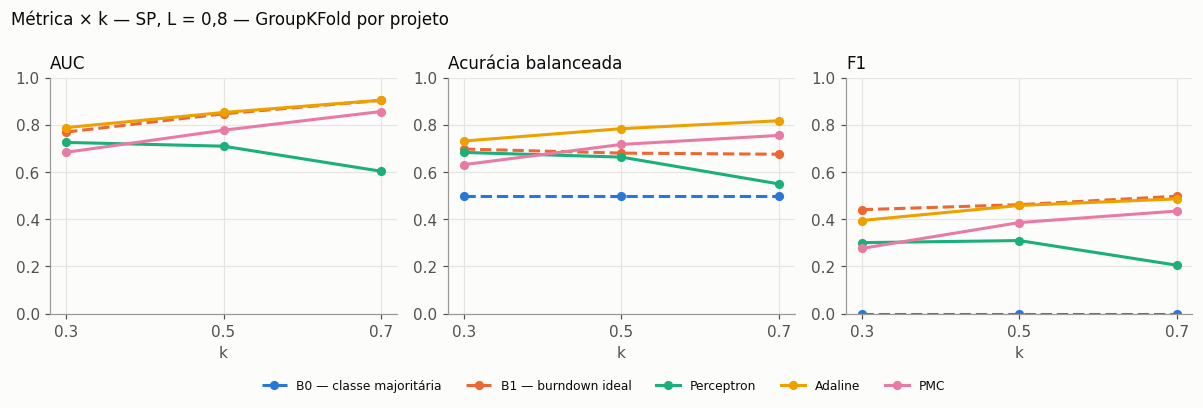

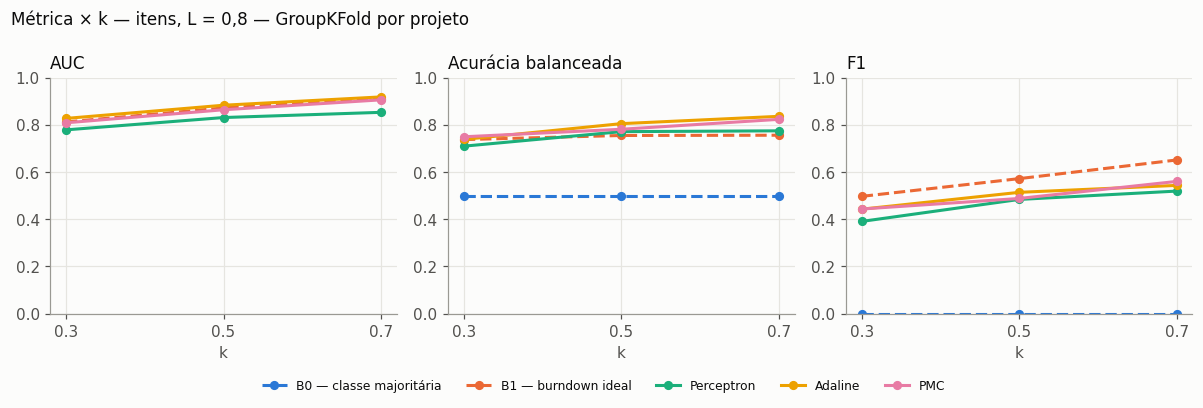

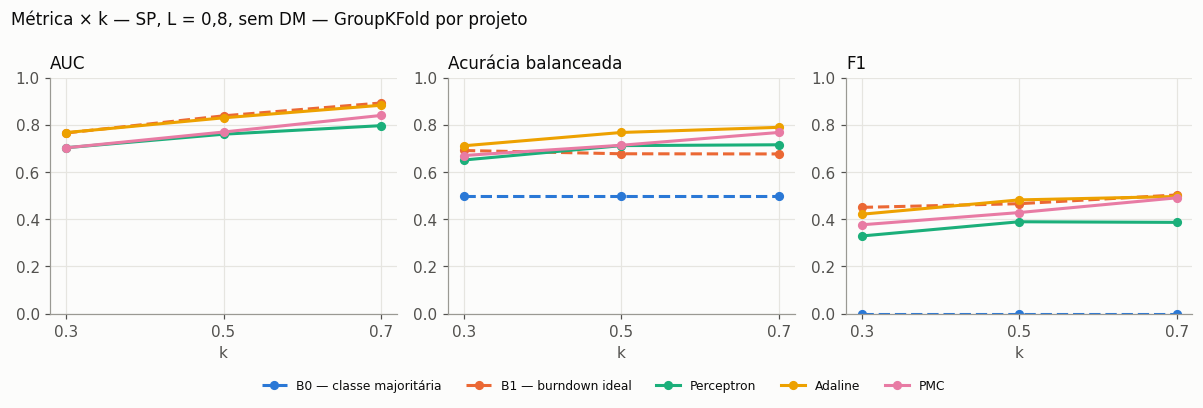

In [14]:
e4 = pd.read_csv('reports/resultados/exp4_avaliacao.csv')
display(e4.pivot_table(index=['cenario','modelo'], columns='k', values=['auc','acuracia_balanceada','f1'], sort=False).round(3))
for c in ['principal', 'robustez', 'sem_DM']:
    display(Image(f'reports/figures/redes/exp4_metrica_vs_k_{c}.png'))